In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Problem 1

In the Metropolis–Hastings, the acceptance probability for moving to y for a symmetric proposal is $A(y|x) \min[1, \pi(y)/\pi(x)]$

What this means is that I need to first sample from a symmetric distribution $A$, given my starting position is $x$. Say $A$ is gaussian. If I sample $l$ from it, I will get $l$ closer to 0 with more probability than say $l$ closer to 100. So the $A(y|x)$ term in the MH formula is already obtained by sampling from $A$.

Say I start from $x=0$ and draw $l$ from a uniform symmetric distribution between $[-0.5, 0.5]$ and get $l=0.4$ which is accepted and I move to $y=0.4$. For the next step, $q(y|x)$ means draw from the same symmetric distribution, but now centered at $x=0.4$, so I need to set $y=$ draw from $[-0.1, 0.9]$ or equivalently $y= x(=0.4)+$ draw from $[-0.5,0.5]$.

The random uniform number $r$ is needed for the final check as we are still dealing with probabilities. If a step $l$ has probabilitity $0.9$ of being accepted, we still need to reject it with probability 0.1, and $r>0.9$ has probability 0.1. 

MH is derived from detailed balance, that is if we follow this algorithm, then after convergence to the target pdf, we will stay in the target pdf. But it does not guarantee this convergence. That requires the markov chain to be irreducible (positive probability of reaching any region of the support in finite steps) and aperiodic. 

We must also start the walker from a position where $\pi(x)\neq 0$ as otherwise the transition probability can get a $\min[1,0/0]$ condition. 

For example, if steps are sampled within $[-1,1]$ but target pdf is uniform within $[-10,-5] \cup [5, 10]$. Say $x_0=5.5$ so the next step can take us in $[4.5,6.5]$. If we want to reach $[-10,-5]$ we will have to take steps in the negative direction but $P_{accept} = \min[1, \pi(4.5)/\pi(5.5)] = \min[1,0]$ as the pdf is $0$ in $[-5,5]$ and no step of size $\leq 2$ can take us from one end to the other. 

So we must pick the proposal distribution accordingly. 

In [3]:
rng = np.random.default_rng()

In [ ]:
def pdf1(x):
    return np.exp(-4.*(x**2-1.)**2)


def metro(N, steps, sigma):

    N = 10000
    steps = 200

    x = np.zeros(N)
    walker = np.zeros(steps+1)
    accepted = 0

    # N random walkers taking 100 steps in accordance to MH acceptance probability

    for i in range(steps):
        y = x+rng.normal(size=N, scale=sigma)
        r = rng.uniform(low=0, high=1, size=N)
        move_mask = np.where(r<np.minimum(1, pdf1(y)/pdf1(x)))
        accepted += np.size(move_mask)

        x[move_mask]=y[move_mask]
        walker[i+1] = x[0]

    fig, ax = plt.subplots(2, 1, figsize=(12, 3))
    xt = np.linspace(-2, 2, 100)

    ax[0].hist(x, bins=100, density=True)
    ax[0].plot(xt, pdf1(xt)*1.05503, label=r'$1.05503 e^{-4(x^2-1)^2}$')
    ax[0].plot(xt, 1/(sigma*np.sqrt(2*np.pi))*np.exp(-0.5*(xt/sigma)**2), '--', label=f'step PDF, s={sigma}')
    ax[0].legend();
    ax[1].plot(walker, label=f'Acceptance Rate = {accepted/(N*steps)}')
    ax[1].legend();

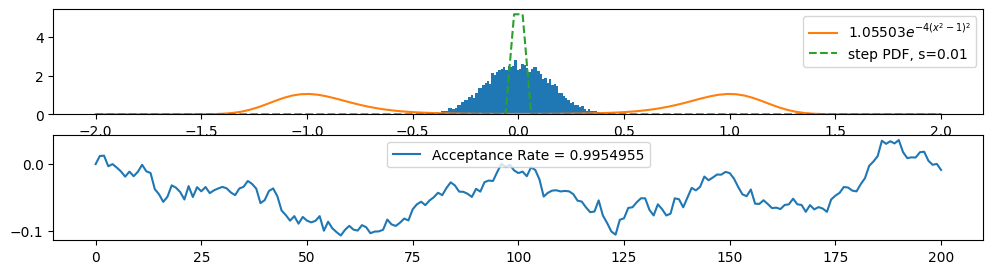

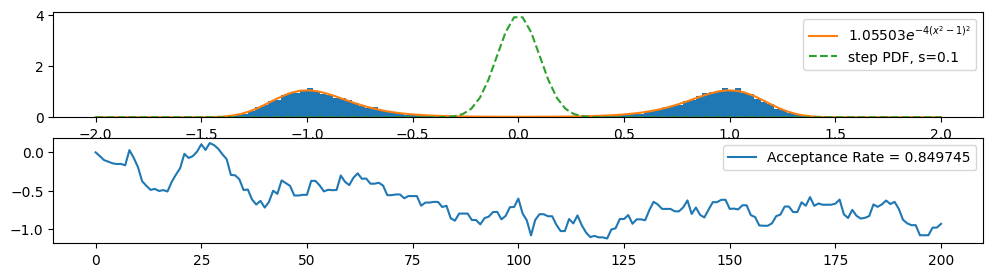

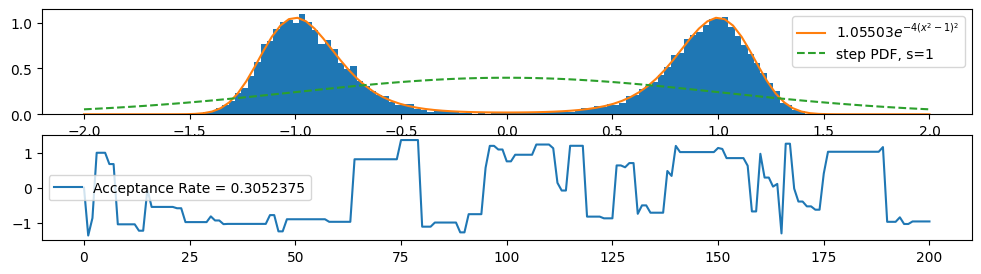

In [102]:
metro(N=10000, steps=200, sigma=0.01)
metro(N=10000, steps=200, sigma=0.1)
metro(N=10000, steps=200, sigma=1)

For smaller $\sigma$ of step PDF and thus smaller steps, the acceptance rate is incredibly high, obviously as taking small steps away from 0 is desirable for the target PDF. Actually any sufficiently small step from any point has $\pi(y)/\pi(x)$ close to 1 and thus will be accepted. However, too small of a step won't converge to the desired PDF for only a 100 steps as seen for $\sigma=0.01$. Large steps often end up getting rejected as they are more likely to move to regions of low probability, but converge to the desired PDF in fewer steps. 

For small steps, walkers usually don't jump between wells as seen by the walkers not crossing 0 again. For larger steps, the walkers frequently cross wells but also stay stagnant more often. 

## Problem 2

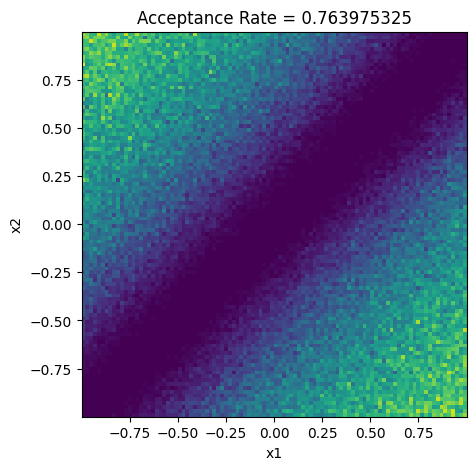

In [ ]:
# Evaluating PDF in log space is more numerically stable

def pdf2(l, x1, x2):
    return -l/np.abs(x1-x2)


def two_particle(N, steps, l):

    delta = 0.2
    accepted = 0

    # row 1 is x1 and row 2 is x2. Randomize initial positions

    x = rng.uniform(low=-delta, high=delta, size=(2,N))

    for i in range(steps):

        U = rng.uniform(low=-delta, high=delta, size=(2, N))
        y = x+U

        r = rng.uniform(low=0, high=1, size=N)
        
        # Have to compute MH condition in log. Simply, log(1)=0 and log(y/x) = log(y)-log(x)
        
        cond = np.exp(np.minimum(0., pdf2(l, y[0, :], y[1,:])-pdf2(l, x[0,:], x[1,:])))

        accept = np.where((y[0, :] >= -1) & (y[0, :] <= 1) &
                        (y[1, :] >= -1) & (y[1, :] <= 1) &
                        (r<cond))

        accepted += np.size(accept)

        x[:, accept] = y[:, accept]

    return x, accepted/(N*steps)


x, ar = two_particle(N=200000, steps=200, l=1)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.set_box_aspect(1)
ax.hist2d(x[0,:], x[1,:], bins=100);
ax.set_xlabel('x1');
ax.set_ylabel('x2');
ax.set_title(f'Acceptance Rate = {ar}');

We get much higher acceptance rates as compared to rejection sampling

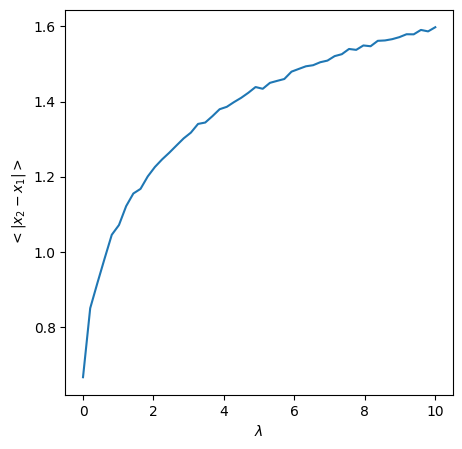

In [190]:
l_vals = np.linspace(0, 10, 50)
d_vals = np.zeros(len(l_vals))
d_vals[0] = 2/3

for i in range(1, len(l_vals)):
    x = two_particle(N=5000, steps=200, l=l_vals[i])
    d_vals[i] = np.average(np.abs(x[0,:]-x[1,:]))

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.plot(l_vals, d_vals)
ax.set_xlabel(r'$\lambda$');
ax.set_ylabel(r'$<|x_2-x_1|>$');